# ДЗ 1. PyTorch: тензоры и автоматическое дифференцирование

Домашнее задание к теме «Введение в PyTorch, автоматическое дифференцирование».
Предполагается, что вы уже прошли материал лекции (`pytorch_basics.ipynb`): базовые операции
с тензорами, линейную алгебру, `backward()`, `torch.autograd.functional.jacobian/hessian`,
работу с Якобианом и Гессианом.

**Как устроено задание.** Два уровня сложности: в первом — три задачи, во втором — одна,
более комплексная. Задачи независимы, можно решать в любом порядке. Ни одна задача не требует
GPU и не займёт больше нескольких минут вычислений на CPU — узкое место везде в том, чтобы
правильно написать код, а не в том, чтобы дождаться обучения.

- **Уровень 1 (базовый).** Уверенное использование того, что было на лекции.
- **Уровень 2 (средний).** Собственный `autograd.Function`, работа с численной устойчивостью.

В каждой задаче есть блок `assert`-проверок — это не полноценные тесты, а быстрый способ
убедиться, что вы не ошиблись в очевидном месте. Проверки проходят — не значит, что решение
идеально; не проходят — значит, точно есть ошибка.


In [1]:
import torch
import numpy as np
import math
torch.manual_seed(0)

## Уровень 1. Попроще

### Задача 1.1. Тензорная разминка

Реализуйте три функции, используя **только** тензорные операции PyTorch (без циклов по элементам
на Python — весь смысл в том, чтобы привыкнуть мыслить «вектором», а не поэлементно).

1. `col_normalize(X)` — для матрицы `X` формы `(n, d)` верните матрицу, в которой каждый
   **столбец** центрирован (вычтено среднее по столбцу) и поделён на своё стандартное отклонение.
2. `pairwise_cosine_sim(X, Y)` — для `X` формы `(n, d)` и `Y` формы `(m, d)` верните матрицу
   `(n, m)` попарных косинусных сходств между строками `X` и строками `Y`. Подсказка: косинусное
   сходство — это скалярное произведение **нормированных** векторов, поэтому всё считается через
   одно матричное умножение нормированных матриц и broadcasting при делении на нормы — без
   единого Python-цикла.
3. `one_hot_with_ignore(labels, n_classes, ignore_index=-1)` — для целочисленного тензора меток
   формы `(n,)` верните one-hot матрицу формы `(n, n_classes)`, в которой строки с
   `labels[i] == ignore_index` должны быть полностью нулевыми (а не one-hot). Посмотрите на
   `torch.scatter_` и булеву индексацию.

**Проверьте себя:** сравните `pairwise_cosine_sim` с эталонной реализацией через
`torch.nn.functional.cosine_similarity` (с `unsqueeze`, чтобы получить broadcasting сразу по двум
осям) — они должны совпадать с точностью до `1e-5`.


In [2]:
def col_normalize(X):
    mean_cols = X.mean(dim=0, keepdim=True)
    std_cols = X.std(dim=0, keepdim=True)
    return (X - mean_cols) / std_cols


def pairwise_cosine_sim(X, Y):
    X_norms = X.norm(dim=1, keepdim=True)
    norm_X = X / X_norms

    Y_norms = Y.norm(dim=1, keepdim=True)
    norm_Y = Y / Y_norms

    return norm_X @ norm_Y.T


def one_hot_with_ignore(labels, n_classes, ignore_index=-1):
    zeros_mat = torch.zeros(labels.shape[0], n_classes)

    src = torch.ones(labels.shape[0])
    src[labels == ignore_index] = 0.0

    print("src:")
    print(src)

    ign_zero_labels = labels.clone()
    ign_zero_labels[ign_zero_labels == ignore_index] = 0

    print("\nign_zero_labels:")
    print(ign_zero_labels)

    print("\nindex:")
    print(ign_zero_labels.unsqueeze(1))

    print("\nsrc:")
    print(src.unsqueeze(1))

    zeros_mat.scatter_(
        dim=1, index=ign_zero_labels.unsqueeze(1), src=src.unsqueeze(1))

    return zeros_mat

# print(torch.nn.functional.cosine_similarity(tensor1.unsqueeze(1), tensor2.unsqueeze(0), dim=2))
# tensor1.unsqueeze(1) - столбец векторов
# tensor2.unsqueeze(0) - строка векторов

In [3]:
labels = torch.tensor([0, 2, -1, 1])
n_classes = 3
print(one_hot_with_ignore(labels, n_classes))

src:
tensor([1., 1., 0., 1.])

ign_zero_labels:
tensor([0, 2, 0, 1])

index:
tensor([[0],
        [2],
        [0],
        [1]])

src:
tensor([[1.],
        [1.],
        [0.],
        [1.]])
tensor([[1., 0., 0.],
        [0., 0., 1.],
        [0., 0., 0.],
        [0., 1., 0.]])


### Задача 1.2. Логистическая регрессия на чистом autograd

Возьмите датасет `sklearn.datasets.load_breast_cancer` (30 числовых признаков, бинарная
классификация: доброкачественная/злокачественная опухоль). Обучите логистическую регрессию
$p(y=1\mid x) = \sigma(w^\top x + b)$, **не используя** `torch.nn` и `torch.optim` — только
тензоры, `requires_grad=True`, ручной шаг градиентного спуска внутри `with torch.no_grad():`,
обнуление градиентов, и функцию потерь — бинарную кросс-энтропию, реализованную вручную (не
пользуйтесь `torch.nn.functional.binary_cross_entropy` и её вариантами).

Стандартизируйте признаки (`StandardScaler` или руками через `mean`/`std`) — без этого
градиентный спуск будет сходиться на порядки медленнее из-за разных масштабов признаков.

**Проверьте себя:** обучите `sklearn.linear_model.LogisticRegression` на тех же
стандартизированных признаках (чтобы сравнение было честным, отключите регуляризацию:
`LogisticRegression(penalty=None)`, а в старых версиях sklearn — `C=1e6`) и сравните полученные
веса, а также итоговую accuracy на обучающей выборке — они должны быть близки.


In [4]:
from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
import pandas as pd

data = load_breast_cancer()

df = pd.DataFrame(data.data, columns=data.feature_names)
X_std = StandardScaler().fit_transform(df)

X = torch.tensor(X_std, dtype=torch.float32)
y = torch.tensor(data.target, dtype=torch.float32)

w = torch.zeros(30, requires_grad=True)
b = torch.zeros(1, requires_grad=True)

lr = 0.1
epochs = 1000

for epoch in range(epochs):
    if w.grad is not None:
        w.grad.zero_()
    if b.grad is not None:
        b.grad.zero_()

    p = 1.0 / (1.0 + torch.exp(-(X @ w + b)))

    eps = 1e-8
    loss = -(y * torch.log(p + eps) + (1 - y) * torch.log(1 - p + eps)).mean()

    loss.backward()

    with torch.no_grad():
        w -= lr * w.grad
        b -= lr * b.grad

sklearn_model = LogisticRegression(C=np.inf, max_iter=1000)
sklearn_model.fit(X, y.ravel())

mask = p.detach() > 0.5
train_acc_torch = (mask.float() == y).float().mean()
train_acc_sklearn = sklearn_model.score(X, y.ravel())

print(f"PyTorch Accuracy: {train_acc_torch:.4f}")
print(f"Sklearn Accuracy: {train_acc_sklearn:.4f}")
print()
print("Весa PyTorch (первые 5):", w.detach()[:5])
print("Веса Sklearn (первые 5):", sklearn_model.coef_[0][:5])

PyTorch Accuracy: 0.9877
Sklearn Accuracy: 0.9930

Весa PyTorch (первые 5): tensor([-0.5573, -0.6300, -0.5407, -0.5866, -0.2313])
Веса Sklearn (первые 5): [ 8.63836738 -0.77527737  7.23578631  3.21414439 -4.56971   ]


### Задача 1.3. Проверка градиентов и охота за багом

**Часть А.** Реализуйте две функции численного градиента функции `f: R^n -> R`:

- `numerical_grad_forward(f, x, eps)` — односторонняя (прямая) разность:
  $\dfrac{\partial f}{\partial x_i} \approx \dfrac{f(x+\epsilon e_i) - f(x)}{\epsilon}$;
- `numerical_grad_central(f, x, eps)` — центральная разность:
  $\dfrac{\partial f}{\partial x_i} \approx \dfrac{f(x+\epsilon e_i) - f(x-\epsilon e_i)}{2\epsilon}$.

Сравните обе с autograd-градиентом на функции $f(x) = \sum_i x_i^3 - \cos(x_1)\cdot x_2$ (или
придумайте свою) для нескольких значений `eps` (например, $10^{-2}, 10^{-4}, 10^{-6}, 10^{-8}$) и
постройте таблицу или график ошибки каждого метода в зависимости от `eps`. Кратко объясните в
markdown-ячейке: почему ошибка центральной разности убывает быстрее (теоретически как
$O(\epsilon^2)$ против $O(\epsilon)$ у односторонней), и почему при слишком маленьком `eps` ошибка
обоих методов снова начинает расти.

**Часть Б.** Ниже — код с сознательно внесённой ошибкой в такой сравнительной проверке (баг
может быть в самой функции, а не в проверке). Найдите ошибку, объясните словами, в чём она, и
исправьте.

```python
def buggy_grad_check():
    def f(x):
        return torch.sin(x[0]) * x[1]**2 + x[0] * x[2]

    x = torch.tensor([1.0, 2.0, 3.0], requires_grad=True)
    y = f(x)
    y.backward()
    grad_auto = x.grad

    # "ручной" аналитический градиент, вычисленный на бумаге (с ошибкой!)
    grad_manual = torch.tensor([
        torch.cos(x[0]) * x[1]**2,
        2 * torch.sin(x[0]) * x[1],
        x[0],
    ])
    print(torch.allclose(grad_auto, grad_manual, atol=1e-4))
```


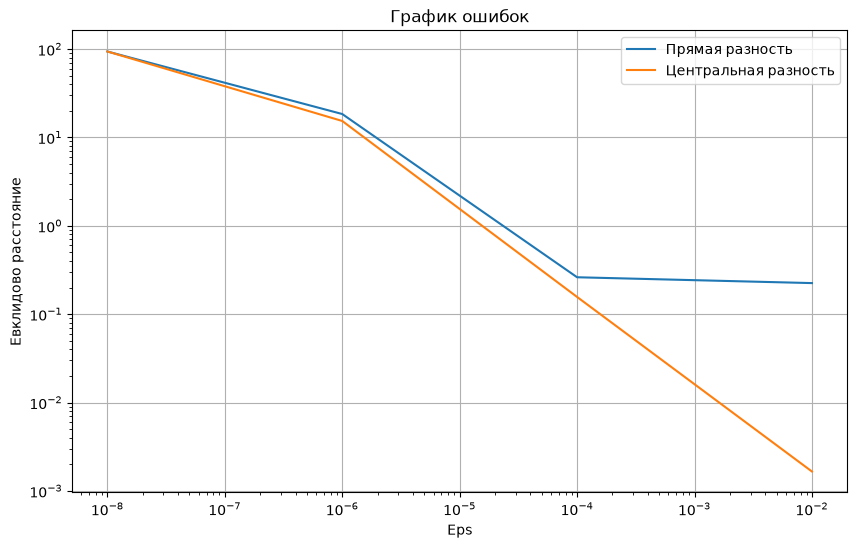

In [5]:
import matplotlib.pyplot as plt


def f(x):
    return torch.sum(x**3) - torch.cos(x[0]) * x[1]


def numerical_grad_forward(f, x, eps):
    n = len(x)
    grad = torch.zeros(n)
    fx = f(x)
    for i in range(n):
        x_plus = x.clone()
        x_plus[i] += eps
        grad[i] = (f(x_plus) - fx) / eps
    return grad


def numerical_grad_central(f, x, eps):
    n = len(x)
    grad = torch.zeros(n)
    for i in range(n):
        x_plus = x.clone()
        x_minus = x.clone()
        x_plus[i] += eps
        x_minus[i] -= eps
        grad[i] = (f(x_plus) - f(x_minus)) / (2 * eps)
    return grad


x_test = torch.tensor([1.0, 2.0, 3.0, 4.0, 5.0], requires_grad=True)
y = f(x_test)
y.backward()
grad_true = x_test.grad.detach()

epsilons = [1e-2, 1e-4, 1e-6, 1e-8]
errors_forward = []
errors_central = []

for eps in epsilons:
    g_fwd = numerical_grad_forward(f, x_test.detach(), eps)
    g_ctr = numerical_grad_central(f, x_test.detach(), eps)

    errors_forward.append(torch.norm(g_fwd - grad_true).item())
    errors_central.append(torch.norm(g_ctr - grad_true).item())

plt.figure(figsize=(10, 6))
plt.loglog(epsilons, errors_forward, label='Прямая разность')
plt.loglog(epsilons, errors_central, label='Центральная разность')
plt.xlabel('Eps')
plt.ylabel('Евклидово расстояние')
plt.title('График ошибок')
plt.legend()
plt.grid(True)
plt.show()

Если рассматривать разложение Тейлора, то когда мы расписываем центральную разность, то сокращается множитель при f'' и остается зависимость от eps^2, а в прямой разности он не сокращается и остается зависимость от eps. При уменьшении epsilon например в 2 раза, ошибка прямой разности уменьшится в 2 раза, а ошибка центральной разности в 4 раза.

При слишком маленьком epsilon ошибка растет

In [6]:
def buggy_grad_check():
    def f(x):
        return torch.sin(x[0]) * x[1]**2 + x[0] * x[2]

    x = torch.tensor([1.0, 2.0, 3.0], requires_grad=True)
    y = f(x)
    y.backward()
    grad_auto = x.grad

    # "ручной" аналитический градиент, вычисленный на бумаге (с ошибкой!)
    grad_manual_error = torch.tensor([
        torch.cos(x[0]) * x[1]**2,  # здесь забыли + x[2]
        2 * torch.sin(x[0]) * x[1],
        x[0],
    ])

    grad_manual = torch.tensor([
        torch.cos(x[0]) * x[1]**2+x[2],  # исправленный вариант
        2 * torch.sin(x[0]) * x[1],
        x[0],
    ])

    print(torch.allclose(grad_auto, grad_manual_error, atol=1e-4))
    print(torch.allclose(grad_auto, grad_manual, atol=1e-4))


buggy_grad_check()

False
True


C:\Users\Lopa\AppData\Local\Temp\ipykernel_24536\3714045952.py:11: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\torch\csrc\autograd\generated\python_variable_methods.cpp:837.)
  grad_manual_error = torch.tensor([


## Уровень 2. Посложнее

### Задача 2. Своя функция для autograd: устойчивый Softplus

Реализуйте класс `StableSoftplus(torch.autograd.Function)`, вычисляющий
$\mathrm{softplus}(x) = \log(1 + e^{x})$ поэлементно, но **численно устойчиво** — то есть без
переполнения `exp` на больших положительных входах. Стандартный приём: для $x > 0$ используйте
тождество $\mathrm{softplus}(x) = x + \log(1 + e^{-x})$ (показатель экспоненты здесь всегда
$\le 0$ и не переполняется), а для $x \le 0$ — прямую формулу $\log(1+e^{x})$, желательно через
`torch.log1p`, которая точнее вычисляет $\log(1+z)$ для маленьких по модулю $z$, чем
`torch.log(1 + z)`.

Вам нужно написать и `forward`, и `backward` вручную (без использования встроенного
`torch.nn.functional.softplus` внутри — иначе задача теряет смысл). Подсказка для `backward`:
производная softplus по $x$ — это в точности сигмоида $\sigma(x) = \dfrac{1}{1+e^{-x}}$.

**Проверьте себя:**
1. `torch.autograd.gradcheck` на вашей функции (в `float64`!) должен проходить.
2. Значение должно совпадать с `torch.nn.functional.softplus` на обычных входах.
3. На входе вида `[1000., -1000., 0.]` ваша функция не должна давать `inf`/`nan` — а наивная
   реализация `torch.log(1 + torch.exp(x))` на таком входе как раз сломается (даст `inf` на
   `1000.`). Продемонстрируйте это явно, сравнив с наивной версией.


In [7]:
# TODO: класс StableSoftplus(torch.autograd.Function)
import torch
import torch.nn.functional as F


class StableSoftplus(torch.autograd.Function):
    @staticmethod
    def forward(ctx, x):
        # Сохраняем входной тензор для использования в backward
        # Это необходимо для вычисления градиентов
        ctx.save_for_backward(x)
        
        # Создаём маску: True там, где x > 0
        positive_mask = x > 0
        
        # Инициализируем выходной тензор того же размера и типа
        result = torch.empty_like(x)
        
        # Для x > 0 используем формулу: x + log(1 + exp(-x))
        # Здесь exp(-x) <= 1, поэтому нет переполнения
        if positive_mask.any():
            result[positive_mask] = x[positive_mask] + torch.log1p(torch.exp(-x[positive_mask]))
        
        # Для x <= 0 используем формулу: log(1 + exp(x))
        # Здесь exp(x) <= 1, тоже безопасно
        # log1p(z) = log(1+z) вычисляется точнее для малых z
        negative_mask = ~positive_mask
        if negative_mask.any():
            result[negative_mask] = torch.log1p(torch.exp(x[negative_mask]))
        
        return result
    
    @staticmethod
    def backward(ctx, grad_output):
        # Восстанавливаем сохранённый входной тензор
        x, = ctx.saved_tensors
        
        # Вычисляем сигмоиду: sigma(x) = 1 / (1 + exp(-x))
        # Это производная softplus по x
        sigmoid_x = torch.sigmoid(x)
        
        # По правилу цепочки: grad_input = grad_output * d(softplus)/dx
        # grad_output уже содержит градиенты от всех последующих операций
        grad_input = grad_output * sigmoid_x
        
        return grad_input


In [8]:
def test_stable_softplus():
    
    # Проверка 1: Сравнение с встроенной функцией на обычных значениях
    print("\nСравнение с torch.nn.functional.softplus на обычных входах:")
    
    x_normal = torch.tensor([-2.0, -1.0, 0.0, 1.0, 2.0], requires_grad=True)
    
    # Наша реализация
    our_result = StableSoftplus.apply(x_normal)
    
    # Встроенная реализация
    builtin_result = F.softplus(x_normal.detach())
    
    print(f"Вход:          {x_normal.detach().tolist()}")
    print(f"Наша версия:   {our_result.tolist()}")
    print(f"Встроенная:    {builtin_result.tolist()}")
    print(f"Макс. разница: {torch.max(torch.abs(our_result - builtin_result)).item():.2e}")
    
    assert torch.allclose(our_result, builtin_result, atol=1e-6), \
        "Результаты не совпадают!"
    print("Результаты совпадают!")
    
    # Численная устойчивость на экстремальных значениях
    print("\nПроверка численной устойчивости на экстремальных значениях:")
    
    x_extreme = torch.tensor([1000.0, -1000.0, 0.0])
    
    # Наивная реализация
    def naive_softplus(x):
        return torch.log(1 + torch.exp(x))
    
    naive_result = naive_softplus(x_extreme)
    our_result_extreme = StableSoftplus.apply(x_extreme)
    builtin_result_extreme = F.softplus(x_extreme)
    
    print(f"Вход:              {x_extreme.tolist()}")
    print(f"Наивная версия:    {naive_result.tolist()}")
    print(f"Наша версия:       {our_result_extreme.tolist()}")
    print(f"Встроенная:        {builtin_result_extreme.tolist()}")
    
    # Проверяем отсутствие inf и nan
    assert not torch.isinf(our_result_extreme).any(), "Есть inf в нашей версии!"
    assert not torch.isnan(our_result_extreme).any(), "Есть nan в нашей версии!"
    print("Нет inf/nan в нашей версии!")
    
    # Наивная версия должна сломаться на x=1000
    assert torch.isinf(naive_result[0]), "Наивная версия должна дать inf на x=1000"
    print("Наивная версия действительно ломается на x=1000 (даёт inf)")
    
    # Проверка градиентов через gradcheck
    print("\nПроверка градиентов через torch.autograd.gradcheck:")
    
    x_grad = torch.randn(5, dtype=torch.float64, requires_grad=True)
    
    try:
        check = torch.autograd.gradcheck(
            StableSoftplus.apply,
            x_grad,
            eps=1e-6,
            atol=1e-4,
            rtol=1e-3
        )
        print("gradcheck пройден успешно!")
    except Exception as e:
        print(f"gradcheck не пройден: {e}")
        raise
    


In [9]:
test_stable_softplus()


Сравнение с torch.nn.functional.softplus на обычных входах:
Вход:          [-2.0, -1.0, 0.0, 1.0, 2.0]
Наша версия:   [0.12692801654338837, 0.3132616877555847, 0.6931471824645996, 1.3132617473602295, 2.1269280910491943]
Встроенная:    [0.12692800164222717, 0.3132616877555847, 0.6931471824645996, 1.31326162815094, 2.1269280910491943]
Макс. разница: 1.19e-07
Результаты совпадают!

Проверка численной устойчивости на экстремальных значениях:
Вход:              [1000.0, -1000.0, 0.0]
Наивная версия:    [inf, 0.0, 0.6931471824645996]
Наша версия:       [1000.0, 0.0, 0.6931471824645996]
Встроенная:        [1000.0, 0.0, 0.6931471824645996]
Нет inf/nan в нашей версии!
Наивная версия действительно ломается на x=1000 (даёт inf)

Проверка градиентов через torch.autograd.gradcheck:
gradcheck пройден успешно!


---
**Что сдавать:** ноутбук с реализованными функциями, пройденными проверками (`assert`) и
короткими ответами на вопросы для решённых задач в markdown-ячейках. Все вычисления в этом
задании занимают на CPU не больше пары минут суммарно — если что-то считается заметно дольше,
скорее всего, в решении есть неэффективность (например, Python-цикл там, где нужна векторизация)
или ошибка, приводящая к дивергенции.
